<a href="https://colab.research.google.com/github/gerardowarbringer-eng/Programacion-para-Analitica-Descrip-Predict/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRACTICA 02 SEMANA 12


* ALUMNO: GERARDO ISIDORO REYES
* MATRÍCULA: 271770




# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [89]:
# Importar bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf

In [90]:
# Lectura del conjunto de Datos
df =pd.read_csv('drive/MyDrive/Unidad03/college.csv')

#I nformación general
print('Información general del conjunto de datos\n')
print(df.info())

# Conversión  de la variable location a categórico
df['location'] = df['location'].astype('category')

# describe() en las variables salary y cost
print(df[['salary', 'cost']].describe())

# Cuenta la cantidad de datos que hay por categoría en location
print(df['location'].value_counts())

# Convierte la variable location usando one-hot encoding
df_encoded = pd.get_dummies(df, columns=['location'])

Información general del conjunto de datos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        85 non-null     int64 
 1   name      85 non-null     object
 2   salary    85 non-null     int64 
 3   cost      85 non-null     int64 
 4   public    85 non-null     object
 5   location  85 non-null     object
dtypes: int64(3), object(3)
memory usage: 4.1+ KB
None
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


In [91]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




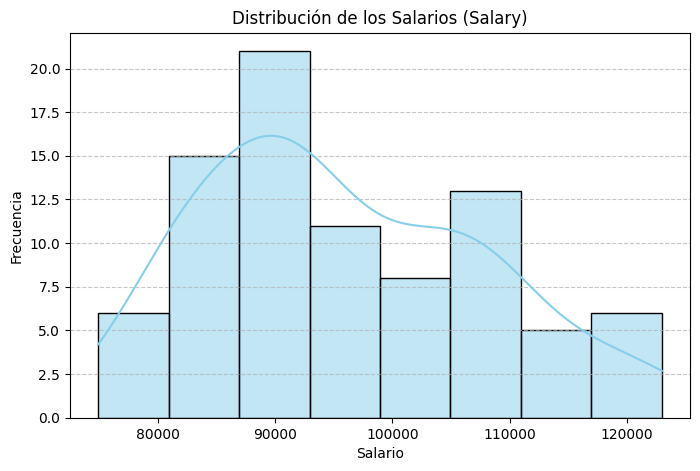

In [92]:
# Histograma salary
plt.figure(figsize=(8, 5))
sns.histplot(df['salary'], kde=True, color='skyblue')
plt.title('Distribución de los Salarios (Salary)')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



* La mayor cantidad de observaciones se agrupa en el rango aproximado de 87,000 a 93,000, alcanzando el pico más alto del gráfico con una frecuencia de 21 datos.

* Sesgo positivo: Se observa una cola extendida hacia la derecha (hacia los salarios más altos entre 105,000 y 123,000), lo que nos indica que la mayoría de los individuos perciben salarios en los rangos medio-bajos de la muestra,  por otro lado hay un grupo más reducido que alcanza los salarios más elevados.

* Se observa un segundo pico o repunte en la frecuencia dentro del rango de 105,000 a 111,000.



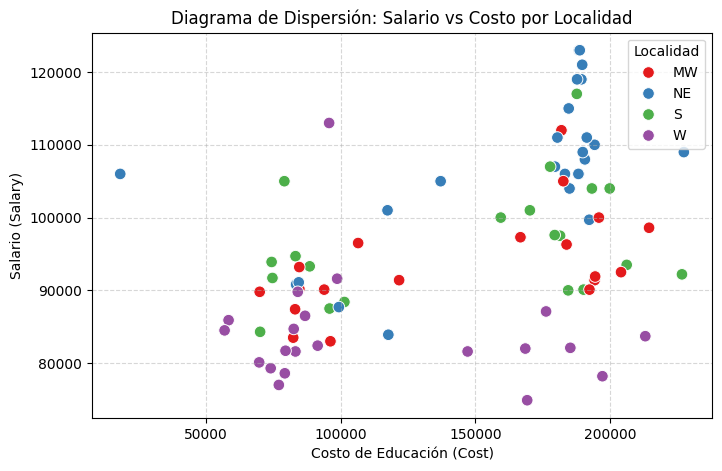

In [93]:
# Diagrama de dispersión: salary vs cost por localidad
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='Set1', s=70)
plt.title('Diagrama de Dispersión: Salario vs Costo por Localidad')
plt.xlabel('Costo de Educación (Cost)')
plt.ylabel('Salario (Salary)')
plt.legend(title='Localidad')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

 Existe una tendencia general donde a mayor Costo de Educación, el Salario tiende a incrementarse. Las instituciones con los costos más elevados (entre $150,000$ y $200,000$) concentran una mayor proporción de salarios altos (superiores a $100,000$).

/tmp/ipykernel_499/1561400310.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='cost', palette='Set2')


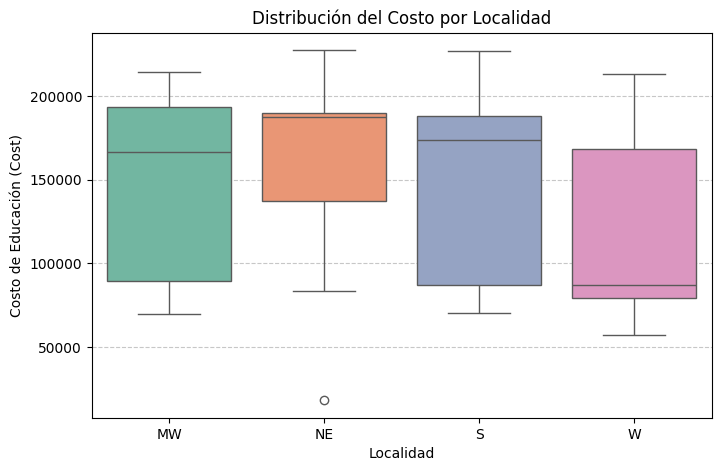

In [94]:
# Boxplot de cost por localidad
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='location', y='cost', palette='Set2')
plt.title('Distribución del Costo por Localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo de Educación (Cost)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Se observa los siguiente

*   Medianas más altas (Costos centrales): Las localidades NE (Noreste) y S (Sur) presentan las medianas de costo más elevadas. En particular, NE tiene la mediana más alta del grupo, ubicándose cerca de los $185,000$.

* Localidad con costos más bajos: La localidad W (Oeste) muestra la mediana más baja del gráfico (ligeramente por debajo de los $90,000$). Además, la mitad de sus datos se concentran en el rango de menor costo.



# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [95]:
# variables predictoras (X) y la variable objetivo (y)
X = pd.get_dummies(df[['cost', 'location']], columns=['location'], drop_first=True, dtype=int)
y = df['salary']

# Ajustar el modelo de regresión lineal
model = LinearRegression()
model.fit(X, y)

# Imprime el intercepto y los coeficientes
print(f"Intercepto (β0): {model.intercept_:.4f}\n")
print("Coeficientes de las variables:")
for col, coef in zip(X.columns, model.coef_):
    print(f"  • {col}: {coef:.4f}")

Intercepto (β0): 84988.7162

Coeficientes de las variables:
  • cost: 0.0605
  • location_NE: 12032.8197
  • location_S: 2800.3450
  • location_W: -7721.4201


*  Intercepto ($\beta_0 = 84988.7162$): Es el salario base estimado para un egresado de la localidad de referencia (MW) cuando el costo de la educación es $0$.

*  cost ($0.0605$): Por cada unidad (dólar) adicional que incrementa el costo de la educación, el salario promedio estimado aumenta en aproximadamente $0.0605$ unidades (es decir, $6.05$ dólares por cada $100$ dólares de costo), manteniendo constante la localidad.

*  location_NE ($12032.8197$): A igual nivel de costo, estar en la localidad Noreste (NE) se asocia con un salario promedio $12,032.82 más alto en comparación con la localidad de referencia (MW). Es el impacto regional positivo más fuerte.

* location_S ($2800.3450$): A igual nivel de costo, estar en la localidad Sur (S) genera un salario promedio $2,800.35 mayor que en la localidad de referencia (MW)


* location_W ($-7721.4201$): A igual nivel de costo, estar en la localidad Oeste (W) reduce el salario promedio estimado en $7,721.42 respecto a la localidad de referencia (MW).


# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

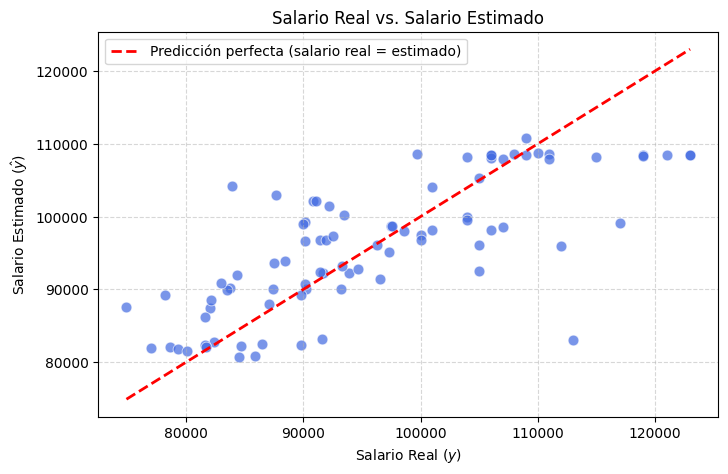

In [96]:
# Obtener las predicciones y calcular los residuos
y_pred = model.predict(X)
residuos = y - y_pred

# Visualización de Salario Estimado vs Salario Real
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y, y=y_pred, color='royalblue', alpha=0.7, s=60)
# Línea de referencia diagonal de predicción perfecta (y = y_pred)
min_val = min(y.min(), y_pred.min())
max_val = max(y.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Predicción perfecta (salario real = estimado)')

plt.title('Salario Real vs. Salario Estimado')
plt.xlabel('Salario Real ($y$)')
plt.ylabel('Salario Estimado ($\\hat{y}$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


*  Los datos presentan una correlación positiva clara; a medida que el salario real ($y$) aumenta, el salario estimado ($\hat{y}$) también tiende a incrementarse, siguiendo la dirección general de la línea roja.

* La línea punteada roja representa los puntos donde la predicción coincide exactamente con el valor real ($y = \hat{y}$). Gran parte de los datos se agrupa de manera cercana alrededor de esta línea, indicando una buena capacidad de desempeño del modelo.


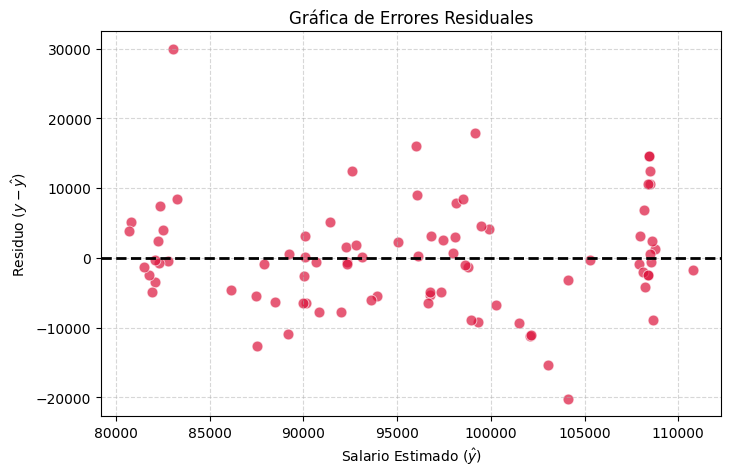

In [97]:
# Visualización: Gráfica de Errores Residuales
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuos, color='crimson', alpha=0.7, s=60)
plt.axhline(y=0, color='black', linestyle='--', lw=2)

plt.title('Gráfica de Errores Residuales')
plt.xlabel('Salario Estimado ($\\hat{y}$)')
plt.ylabel('Residuo ($y - \\hat{y}$)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

*  Los residuos se distribuyen de manera equilibrada tanto por encima como por debajo de la línea de referencia horizontal ($e = 0$), lo que indica que el modelo no presenta un sesgo generalizado de sobreestimación o subestimación sistemática en la media.

*  En términos generales, la amplitud de los errores se mantiene relativamente constante a lo largo de los diferentes niveles de Salario Estimado ($\hat{y}$) (aproximadamente entre $-10,000$ y $+15,000$).  

*  Se observa un punto aislado en la zona de salario estimado bajo (alrededor de $\hat{y} \approx 83,000$) con un residuo significativamente alto de $+30,000$.




# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [98]:
# Obtiene las predicciones del modelo
y_pred = model.predict(X)

# Calcular el Error Cuadrático Medio (MSE)
mse = mean_squared_error(y, y_pred)

# Calcular el "Coeficiente de Determinación" (R²)
r2 = model.score(X, y)

print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 60480269.1466
Coeficiente de Determinación (R²): 0.5705




*   ($R^2 = 0.5705$): El modelo logra explicar aproximadamente el $57.05\%$ de la variabilidad total de los salarios a través del costo de la educación y la ubicación geográfica. El $42.95\%$ restante de la varianza depende de otros factores no incluidos en la regresión (como experiencia laboral, campo de estudio, puesto de trabajo, etc.).

* El modelo ofrece un ajuste aceptable e informativo para identificar tendencias generales, pero muestra un margen de variabilidad considerable si se desea utilizar para predicciones individuales de alta precisión.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [99]:
# Ajusta el modelo de efectos mixtos mediante Mínimos Cuadrados Restringidos (REML)

# 'salary ~ cost' representa la parte fija y 'groups=df["location"]' la componente aleatoria por localidad
vc_model = smf.mixedlm("salary ~ cost", df, groups=df["location"]).fit()

# Muestra la tabla de resultados de Componentes de Varianza
print(vc_model.summary())

# Descomposición explícita de las varianzas
var_inter_grupo = vc_model.cov_re.iloc[0, 0]  # Varianza entre localidades (Group Var)
var_intra_grupo = vc_model.scale             # Varianza residual/dentro de localidades (Scale)
var_total = var_inter_grupo + var_intra_grupo

# Proporción de la variabilidad atribuible a la localidad (Coeficiente de Correlación Intraclase - ICC)
icc = var_inter_grupo / var_total

print("\n--- Descomposición de la Varianza ---")
print(f"Varianza Entre Localidades (Group Var):  {var_inter_grupo:,.2f}")
print(f"Varianza Intra Localidad / Residual:    {var_intra_grupo:,.2f}")
print(f"Varianza Aleatoria Total:               {var_total:,.2f}")
print(f"Correlación Intraclase (ICC):           {icc:.4f} ({icc*100:.2f}%)")

             Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  salary       
No. Observations:    85       Method:              REML         
No. Groups:          4        Scale:               64259988.9170
Min. group size:     19       Log-Likelihood:      -883.7724    
Max. group size:     25       Converged:           Yes          
Mean group size:     21.2                                       
----------------------------------------------------------------
             Coef.     Std.Err.   z    P>|z|   [0.025    0.975] 
----------------------------------------------------------------
Intercept    86475.116 4755.851 18.183 0.000 77153.819 95796.412
cost             0.063    0.017  3.619 0.000     0.029     0.097
Group Var 63375113.891 6902.606                                 


--- Descomposición de la Varianza ---
Varianza Entre Localidades (Group Var):  63,375,113.89
Varianza Intra Localidad / Residual:    64,259,988.92
Varianza Aleatoria T


*   Prácticamente el 50% de la variabilidad del salario no explicada por el costo de la educación se debe exclusivamente a la ubicación geográfica (location). La localidad en la que se estudia/trabaja determina la mitad de las diferencias salariales observadas.

*   Existe una relación directa y estadísticamente significativa entre el costo de la educación y el salario percibido ($\beta_{\text{cost}} = 0.063$, $p < 0.001$). Por cada $100$ dólares adicionales invertidos en la educación, el salario estimado aumenta en promedio en $\$6.30$

* Equidad en las fuentes de variación: La variabilidad total del salario se divide casi en partes iguales entre las diferencias estructurales entre regiones ($\text{Group Var} = 63.38 \text{M}$) y las diferencias individuales dentro de una misma región ($\text{Scale} = 64.26 \text{M}$).

* El rendimiento económico de la inversión en educación depende en gran medida del contexto regional. Un mismo costo educativo no rige por igual en todas las localidades, lo que valida la importancia de incorporar la ubicación como un factor estructural clave en la predicción de salarios.



